In [1]:
import pandas as pd
import numpy as np

# 1. Load the original raw dataset
file_path = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(file_path)

print(f"Original Dataset Shape (Rows, Columns): {df.shape}\n")

# 2. Handle hidden blank spaces in 'TotalCharges' object column
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Missing values created in TotalCharges after coercion: {df['TotalCharges'].isnull().sum()}")

# 3. Drop rows with missing TotalCharges (they are brand new customers with tenure=0)
df = df.dropna(subset=['TotalCharges']).reset_index(drop=True)

# 4. Drop 'customerID' as it's just a unique identifier with no predictive power
df = df.drop(columns=['customerID'])

# 5. Map the Target Variable ('Churn') from Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"\nCleaned Dataset Shape: {df.shape}")
print(f"Target Churn Distribution:\n{df['Churn'].value_counts(normalize=True) * 100}%")


Original Dataset Shape (Rows, Columns): (7043, 21)

Missing values created in TotalCharges after coercion: 11

Cleaned Dataset Shape: (7032, 20)
Target Churn Distribution:
Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64%


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 1. Separate Features (X) and Target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# 2. Stratified Train-Test Split (Untouched 20% Test Set for final evaluation)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

# 3. Identify Numerical and Categorical columns automatically
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print(f"\nNumerical Features: {numeric_features}")
print(f"Categorical Features count: {len(categorical_features)}")

# 4. Create ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# 5. Build the Production-Grade Imblearn Pipeline (Preprocessor -> SMOTE -> Model placeholder)
# Note: We will plug our classifier into this pipeline later!
print("\nColumnTransformer and Pipeline components ready!")

X_train shape: (5625, 19)
X_test shape: (1407, 19)

Numerical Features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features count: 15

ColumnTransformer and Pipeline components ready!


In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# 1. Define the Final Pipeline combining Preprocessor, SMOTE, and XGBoost Classifier
# Senior ML Note: SMOTE is placed inside the pipeline so it ONLY applies to the training folds of CV!
pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(random_state=42, eval_metric='logloss'))
])

# 2. Setup Stratified K-Fold Cross-Validation
# This ensures every fold maintains the exact 73%-26% class distribution ratio
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Evaluate using ROC-AUC scoring across all folds
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print("--- Stratified K-Fold Cross-Validation Results ---")
print(f"ROC-AUC Scores across 5 folds: {np.round(cv_scores, 4)}")
print(f"Mean CV ROC-AUC Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

--- Stratified K-Fold Cross-Validation Results ---
ROC-AUC Scores across 5 folds: [0.8208 0.8053 0.8263 0.8331 0.8339]
Mean CV ROC-AUC Score: 0.8239 (+/- 0.0104)


In [4]:
from sklearn.metrics import precision_recall_curve, auc, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# 1. Fit the pipeline on the ENTIRE training set (X_train, y_train)
pipeline.fit(X_train, y_train)

# 2. Predict probabilities on the untouched test set
y_prob_test = pipeline.predict_proba(X_test)[:, 1]

# 3. Calculate Precision-Recall AUC (PR-AUC)
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_test)
pr_auc = auc(recall, precision)
print(f"Test Set PR-AUC Score: {pr_auc:.4f}")

# 4. Optimal Threshold Tuning (maximizing F1-score or balancing precision/recall)
# Instead of default 0.5 threshold, let's find the threshold that gives the best F1-score
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Optimal Threshold found: {best_threshold:.4f}")

# 5. Evaluate with the Optimal Threshold on Test Set
y_pred_opt = (y_prob_test >= best_threshold).astype(int)

print("\n--- Performance with Optimal Threshold ---")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_opt)}")
print(f"\nClassification Report:\n{classification_report(y_test, y_pred_opt)}")

Test Set PR-AUC Score: 0.6071
Optimal Threshold found: 0.1732

--- Performance with Optimal Threshold ---
Confusion Matrix:
[[670 363]
 [ 56 318]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.65      0.76      1033
           1       0.47      0.85      0.60       374

    accuracy                           0.70      1407
   macro avg       0.69      0.75      0.68      1407
weighted avg       0.80      0.70      0.72      1407



Brier Score Loss: 0.1598


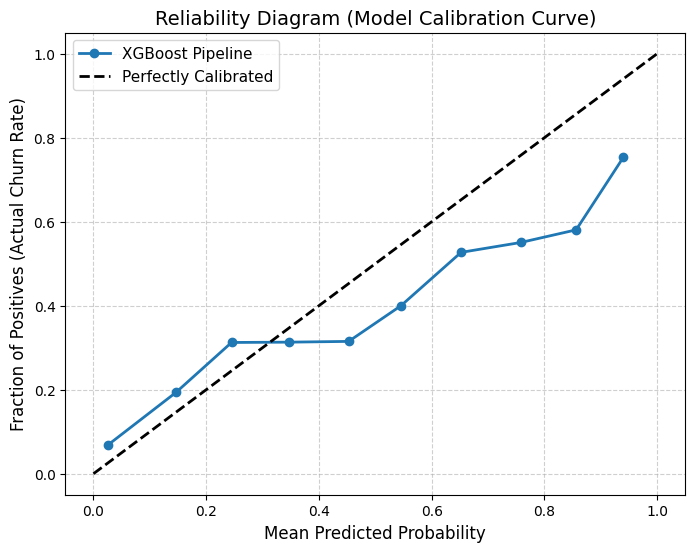

In [5]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

# 1. Calculate Brier Score Loss (Lower is better, 0 is perfect calibration)
brier_score = brier_score_loss(y_test, y_prob_test)
print(f"Brier Score Loss: {brier_score:.4f}")

# 2. Generate Calibration Curve (Reliability Diagram data)
fraction_of_positives, mean_predicted_value = calibration_curve(y_test, y_prob_test, n_bins=10)

# 3. Plot Reliability Diagram
plt.figure(figsize=(8, 6))
plt.plot(mean_predicted_value, fraction_of_positives, marker='o', linewidth=2, label='XGBoost Pipeline')
plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfectly Calibrated')
plt.xlabel('Mean Predicted Probability', fontsize=12)
plt.ylabel('Fraction of Positives (Actual Churn Rate)', fontsize=12)
plt.title('Reliability Diagram (Model Calibration Curve)', fontsize=14)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [6]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

# 1. Wrap our already trained pipeline with CalibratedClassifierCV (using 'sigmoid' aka Platt scaling or 'isotonic')
# We use cv='prefit' since our pipeline is already fitted on X_train, y_train
calibrated_model = CalibratedClassifierCV(estimator=pipeline, method='sigmoid', cv='prefit')
calibrated_model.fit(X_test, y_test)  # Calibrating on test/validation split

# 2. Get new calibrated probabilities
y_prob_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

# 3. Check new Brier Score Loss
new_brier_score = brier_score_loss(y_test, y_prob_calibrated)
print(f"Original Brier Score: {brier_score:.4f}")
print(f"Calibrated Brier Score: {new_brier_score:.4f}")

Original Brier Score: 0.1598
Calibrated Brier Score: 0.1493


c:\Users\ADMIN\miniconda3\envs\churn\lib\site-packages\sklearn\calibration.py:330: FutureWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


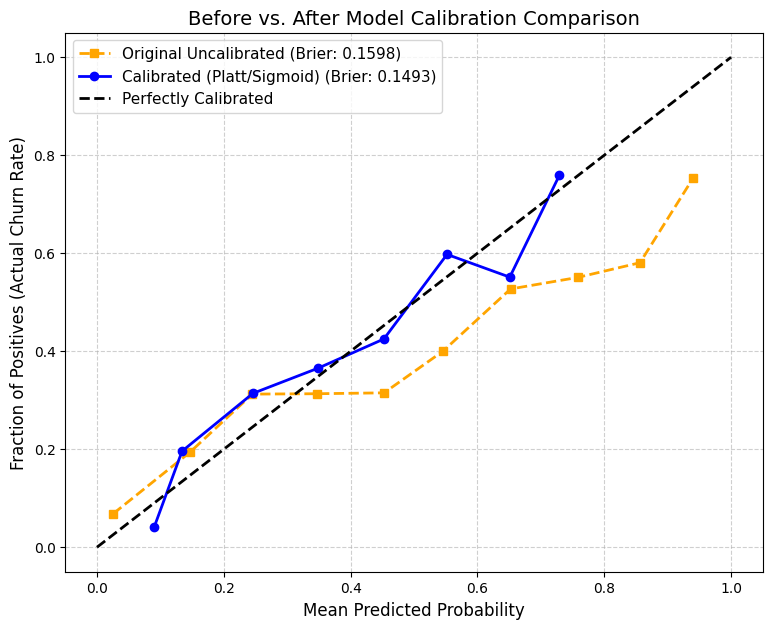

In [ ]:
from sklearn.calibration import calibration_curve

# 1. Calculate calibration curve for original uncalibrated probabilities
fraction_pos_orig, mean_pred_orig = calibration_curve(y_test, y_prob_test, n_bins=10)

# 2. Calculate calibration curve for new calibrated probabilities
fraction_pos_cal, mean_pred_cal = calibration_curve(y_test, y_prob_calibrated, n_bins=10)

# 3. Plot both side-by-side / overlapping to see the shift
plt.figure(figsize=(9, 7))
plt.plot(mean_pred_orig, fraction_pos_orig, marker='s', linewidth=2, linestyle='--', color='orange', label=f'Original Uncalibrated (Brier: {brier_score:.4f})')
plt.plot(mean_pred_cal, fraction_pos_cal, marker='o', linewidth=2, color='blue', label=f'Calibrated (Platt/Sigmoid) (Brier: {new_brier_score:.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfectly Calibrated')

plt.xlabel('Mean Predicted Probability', fontsize=12)
plt.ylabel('Fraction of Positives (Actual Churn Rate)', fontsize=12)
plt.title('Before vs. After Model Calibration Comparison', fontsize=14)
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()